# House Price Prediction — IDSE Data Mining Project

This notebook covers the full workflow from raw data inspection to a reusable prediction model.

**Dataset note:** The bundled Indian housing-style dataset is synthetic and reproducible, not actual property transactions. Prices are in ₹ lakhs.

## 1. Problem statement
Estimate a residential property's price from its city, locality type, area, room count, age, parking, furnishing and other attributes. Since the target is continuous, this is a supervised regression task.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, json, joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(ROOT/"data"/"indian_house_prices.csv")
print("Shape:",df.shape)
df.head()

Shape: (1812, 13)


,city,locality_type,area_sqft,bedrooms,bathrooms,property_age,parking_spaces,floor_number,furnishing_status,property_type,distance_to_city_km,main_road_access,price_lakhs
0,Pune,IT Corridor,1682.0,4,4,30,1.0,4,Semi-furnished,Independent House,11.1,Yes,54.12
1,Bengaluru,Residential,1419.0,4,4,32,1.0,11,Semi-furnished,Apartment,NaN,No,49.93
2,Coimbatore,Suburban,1457.0,2,2,5,1.0,12,Semi-furnished,Apartment,6.4,Yes,50.43
3,Pune,Residential,1792.0,4,5,18,1.0,15,Unfurnished,Independent House,7.0,Yes,57.73
4,Hyderabad,Residential,1072.0,3,3,26,1.0,6,Unfurnished,Apartment,2.8,Yes,44.81


## 2. Initial inspection and cleaning
Review types, summaries, missing values and duplicates. Exact duplicates are removed. Missing values are imputed inside the pipeline so that the imputer learns only from training data.

In [2]:
display(df.info())
display(df.describe(include="all").T)
display(df.isna().sum())
before=len(df)
df=df.drop_duplicates().copy()
print("Duplicate rows removed:",before-len(df)," | Rows remaining:",len(df))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1812 entries, 0 to 1811
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   city                 1812 non-null   object 
 1   locality_type        1812 non-null   object 
 2   area_sqft            1812 non-null   float64
 3   bedrooms             1812 non-null   int64  
 4   bathrooms            1812 non-null   int64  
 5   property_age         1812 non-null   int64  
 6   parking_spaces       1790 non-null   float64
 7   floor_number         1812 non-null   int64  
 8   furnishing_status    1780 non-null   object 
 9   property_type        1812 non-null   object 
 10  distance_to_city_km  1766 non-null   float64
 11  main_road_access     1812 non-null   object 
 12  price_lakhs          1812 non-null   float64
dtypes: float64(4), int64(4), object(5)
memory usage: 184.2+ KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
city,1812,6,Hyderabad,428,NaN,NaN,NaN,NaN,NaN,NaN,NaN
locality_type,1812,5,Suburban,472,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area_sqft,1812.0,NaN,NaN,NaN,1445.516004,506.142601,450.0,1081.75,1435.5,1767.0,3246.0
bedrooms,1812.0,NaN,NaN,NaN,3.12638,1.20097,1.0,2.0,3.0,4.0,6.0
bathrooms,1812.0,NaN,NaN,NaN,3.098786,1.241496,1.0,2.0,3.0,4.0,5.0
property_age,1812.0,NaN,NaN,NaN,17.364238,10.419569,0.0,8.0,17.0,26.0,35.0
parking_spaces,1790.0,NaN,NaN,NaN,1.368715,0.802681,0.0,1.0,1.0,2.0,3.0
floor_number,1812.0,NaN,NaN,NaN,8.077815,4.333682,1.0,4.0,8.0,12.0,15.0
furnishing_status,1780,3,Unfurnished,780,NaN,NaN,NaN,NaN,NaN,NaN,NaN
property_type,1812,3,Apartment,1171,NaN,NaN,NaN,NaN,NaN,NaN,NaN


city                    0
locality_type           0
area_sqft               0
bedrooms                0
bathrooms               0
property_age            0
parking_spaces         22
floor_number            0
furnishing_status      32
property_type           0
distance_to_city_km    46
main_road_access        0
price_lakhs             0
dtype: int64

Duplicate rows removed: 12  | Rows remaining: 1800


## 3. Exploratory data analysis
Inspect the price distribution, city-wise price spread, area-price relationship and numeric correlations. These are associations in the generated dataset, not causal claims.

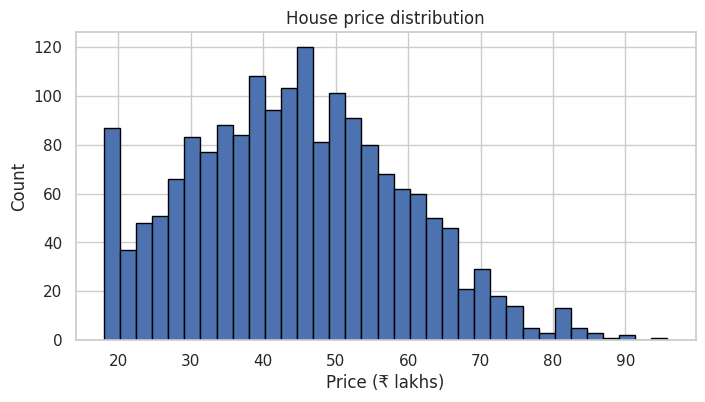

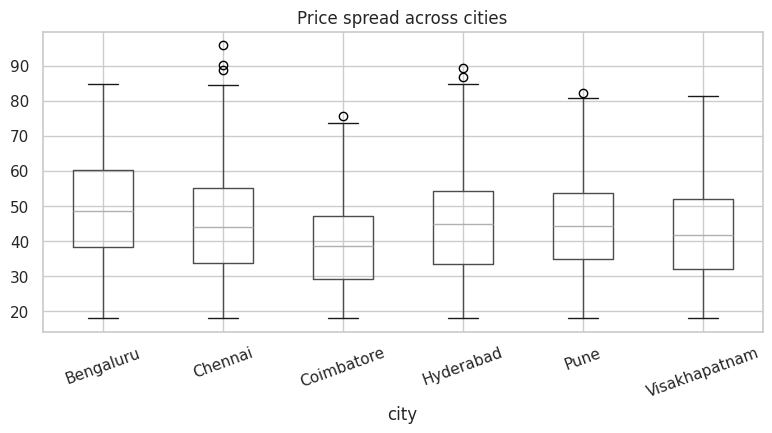

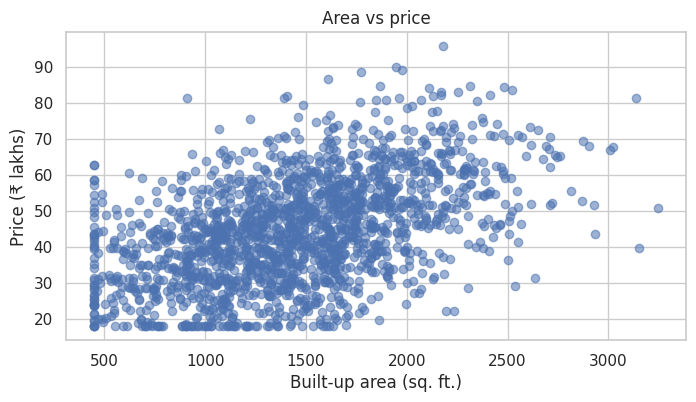

,area_sqft,bedrooms,bathrooms,property_age,distance_to_city_km,price_lakhs
area_sqft,1.00,0.81,0.71,0.04,-0.00,0.49
bedrooms,0.81,1.00,0.88,0.05,-0.03,0.48
bathrooms,0.71,0.88,1.00,0.04,-0.02,0.45
property_age,0.04,0.05,0.04,1.00,-0.03,-0.26
distance_to_city_km,-0.00,-0.03,-0.02,-0.03,1.00,-0.19
price_lakhs,0.49,0.48,0.45,-0.26,-0.19,1.00


In [3]:
sns.set_theme(style="whitegrid")
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(df.price_lakhs,bins=35,edgecolor="black")
ax.set(title="House price distribution",xlabel="Price (₹ lakhs)",ylabel="Count")
plt.show()
fig,ax=plt.subplots(figsize=(9,4))
df.boxplot(column="price_lakhs",by="city",rot=20,ax=ax)
ax.set_title("Price spread across cities"); plt.suptitle(""); plt.show()
fig,ax=plt.subplots(figsize=(8,4))
ax.scatter(df.area_sqft,df.price_lakhs,alpha=.55)
ax.set(xlabel="Built-up area (sq. ft.)",ylabel="Price (₹ lakhs)",title="Area vs price")
plt.show()
display(df[["area_sqft","bedrooms","bathrooms","property_age","distance_to_city_km","price_lakhs"]].corr().round(2))

## 4. Feature preparation
Numeric columns are median-imputed and scaled. Categorical columns are mode-imputed and one-hot encoded. The preprocessing steps are bundled with each estimator in a Scikit-learn pipeline.

In [4]:
TARGET="price_lakhs"
NUM=["area_sqft","bedrooms","bathrooms","property_age","parking_spaces","floor_number","distance_to_city_km"]
CAT=["city","locality_type","furnishing_status","property_type","main_road_access"]
FEATURES=NUM+CAT
X,y=df[FEATURES],df[TARGET]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42)
pre=ColumnTransformer([
 ("num",Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())]),NUM),
 ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("encode",OneHotEncoder(handle_unknown="ignore"))]),CAT)
])
print("Training rows:",len(X_train)," Test rows:",len(X_test))

Training rows: 1440  Test rows: 360


## 5. Model training and comparison
Linear Regression provides a baseline; Ridge adds regularisation. Random Forest and Extra Trees can capture non-linear patterns. All models use the same train/test split.

In [5]:
candidates={
 "Linear Regression":LinearRegression(),
 "Ridge Regression":Ridge(alpha=2),
 "Random Forest":RandomForestRegressor(n_estimators=180,min_samples_leaf=2,random_state=42,n_jobs=-1),
 "Extra Trees":ExtraTreesRegressor(n_estimators=180,min_samples_leaf=2,random_state=42,n_jobs=-1)
}
fitted={}; rows=[]
for name,est in candidates.items():
 pipe=Pipeline([("preprocessor",pre),("model",est)])
 pipe.fit(X_train,y_train); pred=pipe.predict(X_test); fitted[name]=pipe
 rows.append({"Model":name,"MAE":mean_absolute_error(y_test,pred),
              "RMSE":mean_squared_error(y_test,pred)**.5,"R2":r2_score(y_test,pred)})
comparison=pd.DataFrame(rows).sort_values("RMSE")
display(comparison.round(3))

,Model,MAE,RMSE,R2
1,Ridge Regression,6.130,7.727,0.728
0,Linear Regression,6.130,7.728,0.728
2,Random Forest,7.188,9.032,0.628
3,Extra Trees,7.246,9.148,0.619


## 6. Hyperparameter tuning
Tune a Random Forest using three-fold cross-validation on the training set. The tuned model is compared against the best untuned candidate on the held-out test split.

In [6]:
rf=Pipeline([("preprocessor",pre),("model",RandomForestRegressor(random_state=42,n_jobs=-1))])
search=GridSearchCV(rf,{"model__n_estimators":[140,220],
 "model__max_depth":[None,18],"model__min_samples_leaf":[1,2]},
 cv=3,scoring="neg_root_mean_squared_error",n_jobs=-1)
search.fit(X_train,y_train)
base_name=comparison.iloc[0].Model
base_model=fitted[base_name]
base_pred=base_model.predict(X_test)
tuned_pred=search.best_estimator_.predict(X_test)
if mean_squared_error(y_test,tuned_pred)<=mean_squared_error(y_test,base_pred):
 final_model,final_name=search.best_estimator_,"Tuned Random Forest"
else:
 final_model,final_name=base_model,base_name
final_pred=final_model.predict(X_test)
print("Best RF parameters:",search.best_params_,"\nSelected model:",final_name)

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Best RF parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 220} 
Selected model: Ridge Regression


## 7. Evaluation and error analysis
MAE is the average absolute error in lakhs. RMSE penalises larger errors more strongly. R² measures explained variation on this test split. Residual plots help check whether errors have a visible pattern.

,Model,MAE (lakhs),RMSE (lakhs),R2
0,Ridge Regression,6.13,7.727,0.728


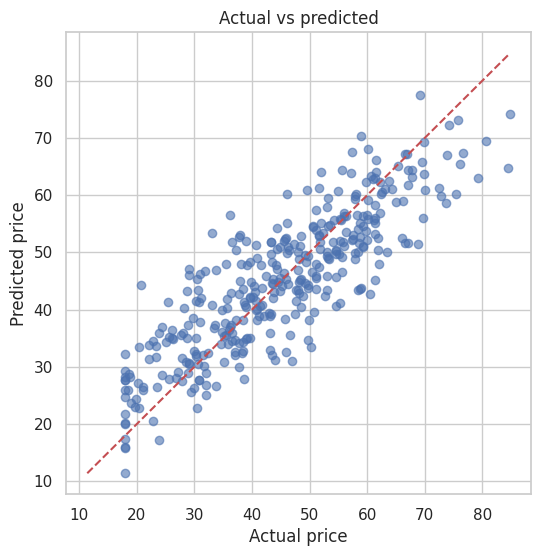

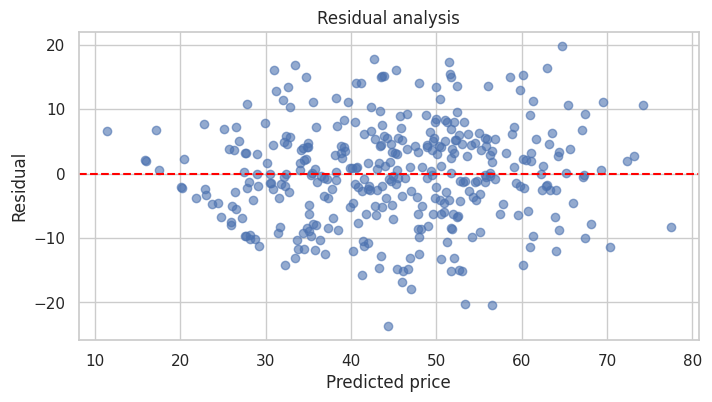

In [7]:
metrics={"Model":final_name,"MAE (lakhs)":mean_absolute_error(y_test,final_pred),
 "RMSE (lakhs)":mean_squared_error(y_test,final_pred)**.5,"R2":r2_score(y_test,final_pred)}
display(pd.DataFrame([metrics]).round(3))
fig,ax=plt.subplots(figsize=(6,6)); ax.scatter(y_test,final_pred,alpha=.6)
lo,hi=min(y_test.min(),final_pred.min()),max(y_test.max(),final_pred.max())
ax.plot([lo,hi],[lo,hi],"r--"); ax.set(xlabel="Actual price",ylabel="Predicted price",title="Actual vs predicted")
plt.show()
fig,ax=plt.subplots(figsize=(8,4)); ax.scatter(final_pred,y_test-final_pred,alpha=.6)
ax.axhline(0,color="red",linestyle="--"); ax.set(xlabel="Predicted price",ylabel="Residual",title="Residual analysis")
plt.show()

## 8. Save the pipeline and try a prediction
The saved pipeline contains both preprocessing and the estimator, so a new property can be passed in using the original columns.

In [8]:
(ROOT/"models").mkdir(exist_ok=True); (ROOT/"outputs").mkdir(exist_ok=True)
joblib.dump(final_model,ROOT/"models"/"house_price_pipeline.joblib")
comparison.to_csv(ROOT/"outputs"/"model_comparison.csv",index=False)
summary={"model":final_name,"MAE_lakhs":float(metrics["MAE (lakhs)"]),
 "RMSE_lakhs":float(metrics["RMSE (lakhs)"]),"R2":float(metrics["R2"]),
 "best_random_forest_params":search.best_params_}
(ROOT/"models"/"metrics.json").write_text(json.dumps(summary,indent=2))
sample=pd.DataFrame([{"area_sqft":1450,"bedrooms":3,"bathrooms":2,"property_age":5,
 "parking_spaces":1,"floor_number":4,"distance_to_city_km":6.5,"city":"Hyderabad",
 "locality_type":"Residential","furnishing_status":"Semi-furnished",
 "property_type":"Apartment","main_road_access":"Yes"}])
print(f"Estimated price: ₹{final_model.predict(sample)[0]:.2f} lakhs")

Estimated price: ₹44.57 lakhs


## 9. Conclusion and limitations
The notebook demonstrates the full regression workflow, from inspecting raw data to saving a reusable model. The dataset is synthetic and simplified; the model is an educational demonstration and must not be used for real property decisions. Future work could use verified sales data, more detailed location information, validation across regions and time periods, and prediction intervals.